# Lead Service Line Needs and a Proposed Xylem Market Approach

**Darsh Rathi | Xylem / IBM SkillsBuild project | Portfolio remaster | October 11, 2026**

## Research question
**Where are lead service line infrastructure needs greatest across U.S. states?**

## Proposed business application
Xylem should use state inventory patterns to identify candidate markets for tailored identification and replacement-planning services, then assess individual utilities before selecting pilots.

The analysis supports three illustrative service emphases: identification in Texas and Pennsylvania, replacement planning in Illinois, and parallel work in Ohio and New York. These examples are based on reported inventory mix. They are not statistical clusters, a comprehensive market ranking, or evidence that utilities are ready to buy or implement a service.

The notebook preserves the original EPA 2026 Q2 analytical sample and calculations, adds reporting coverage, and makes the evidence behind the recommendation explicit. The recommendation is a portfolio proposal; no pilot or commercial result is claimed.

**Identification Need = Lead Status Unknown. Known Replacement Inventory = Lead + Galvanized Requiring Replacement (GRR).** Unknown does not mean lead. Inventory does not measure exposure or water quality.


## 1. Data Source

The primary dataset is the EPA SDWIS Service Line Inventory for 2026 Q2.

**Raw file:** `SDWIS_service_line_inventory_2026Q2.csv`

**Official source:** [U.S. EPA SDWIS Service Line Inventory](https://sdwis.epa.gov/ords/sfdw_pub/r/sfdw/sdwis_fed_reports_public/service-line-inventory)

The original CSV is preserved unchanged. All filtering, cleaning, calculations, validation checks, and aggregation are performed reproducibly within this notebook.

Relevant fields include:

- Lead service lines
- Galvanized Requiring Replacement (GRR) service lines
- Lead Status Unknown service lines
- Non-lead service lines
- Total reported service lines
- Public Water System (PWS) type
- Service-line reporting status
- Primacy agency
- EPA region
- Population served

The analysis focuses on reported infrastructure inventories. It does not measure household lead exposure, drinking-water lead concentrations, or health risk.

## 2. Analytical Framework

Lead service line infrastructure need is treated as a multidimensional issue rather than a single ranking.

For this analysis:

**Known Replacement Inventory = Lead Service Lines + Galvanized Requiring Replacement Service Lines**

This represents service lines already classified into categories requiring lead-related replacement action.

**Identification Need = Lead Status Unknown Service Lines**

This represents service lines whose material classification remains unresolved.

These measures represent different stages of the same infrastructure process:

**Unknown → Identify material → Classify as Lead / GRR / Non-lead → Replace where required**

The analysis does not combine replacement and identification needs into a single composite score.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/raw").is_dir() and (ROOT / "REMASTER/data/raw").is_dir():
    ROOT = ROOT / "REMASTER"
DATA = ROOT / "data/raw"
OUTPUT = ROOT / "results"
assert DATA.is_dir(), "Run the notebook from the REMASTER folder or its parent."
OUTPUT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", None)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#102A43", "text.color": "#102A43",
    "axes.titleweight": "bold", "figure.facecolor": "white",
})


Matplotlib is building the font cache; this may take a moment.


## 3. Load Raw Data

The EPA CSV is loaded directly from the preserved raw file.

The file requires `cp1252` character encoding. `low_memory=False` is used so pandas reads the dataset without chunk-based type inference.

No cleaning or transformations are performed during this step.

In [2]:
raw_df = pd.read_csv(
    DATA / "SDWIS_service_line_inventory_2026Q2.csv",
    encoding="cp1252",
    low_memory=False
)

print(f"Rows: {raw_df.shape[0]:,}")
print(f"Columns: {raw_df.shape[1]}")

Rows: 66,429
Columns: 22


In [3]:
raw_df["Submission Year Quarter"].value_counts(dropna=False)

Submission Year Quarter
2026Q2    66429
Name: count, dtype: int64

## 4. Initial Data Inspection

Before filtering or cleaning, the raw dataset is inspected for its structure, data types, missing values, and reporting completeness.

In [4]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66429 entries, 0 to 66428
Data columns (total 22 columns):
 #   Column                                            Non-Null Count  Dtype 
---  ------                                            --------------  ----- 
 0   Submission Year Quarter                           66429 non-null  object
 1   PWS ID                                            66429 non-null  object
 2   PWS Name                                          66429 non-null  object
 3   # Galvanized Requiring Replacement Service Lines  59062 non-null  object
 4   # Lead Service Lines                              58918 non-null  object
 5   # Lead Status Unknown Service Lines               59652 non-null  object
 6   # Non-lead Service Lines                          59620 non-null  object
 7   Total # Service Lines Reported                    60109 non-null  object
 8   Any Service Line Type Reported                    66429 non-null  object
 9   Service Line Report Status  

In [5]:
relevant_columns = [
    "# Lead Service Lines",
    "# Galvanized Requiring Replacement Service Lines",
    "# Lead Status Unknown Service Lines",
    "# Non-lead Service Lines",
    "Total # Service Lines Reported",
    "Population Served Count"
]

raw_df[relevant_columns].isna().sum()

# Lead Service Lines                                7511
# Galvanized Requiring Replacement Service Lines    7367
# Lead Status Unknown Service Lines                 6777
# Non-lead Service Lines                            6809
Total # Service Lines Reported                      6320
Population Served Count                                0
dtype: int64

In [6]:
raw_df["PWS Type"].value_counts()

PWS Type
Community water system                49378
Non-Transient non-community system    17051
Name: count, dtype: int64

In [7]:
raw_df["Service Line Report Status"].value_counts()

Service Line Report Status
Reported all required service line types          58825
Did not report any required service line types     6674
Reported some but not all service line types        930
Name: count, dtype: int64

### Initial Inspection Notes

The raw file contains multiple water-system types and reporting-completeness levels. Several service-line count fields also contain missing values and are stored as text because some values include commas.

The analysis will therefore restrict the sample to Community Water Systems with complete required service-line reporting, preserve missing values during numeric conversion, and explicitly limit the geographic comparison to the 50 states and District of Columbia.

## 5. Define Analytical Scope

The main analysis focuses on Community Water Systems with complete required service-line reporting in the 50 U.S. states and District of Columbia.

These filters are applied sequentially so the effect of each scope decision can be verified.

In [8]:
df = raw_df[
    raw_df["PWS Type"] == "Community water system"
].copy()

print(f"Community Water Systems: {len(df):,}")

Community Water Systems: 49,378


In [9]:
df = df[
    df["Service Line Report Status"] == "Reported all required service line types"
].copy()

print(f"Complete Community Water System reports: {len(df):,}")

Complete Community Water System reports: 44,957


In [10]:
states_dc = [
    "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado",
    "Connecticut", "Delaware", "District of Columbia", "Florida", "Georgia",
    "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky",
    "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota",
    "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
    "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota",
    "Ohio", "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island",
    "South Carolina", "South Dakota", "Tennessee", "Texas", "Utah", "Vermont",
    "Virginia", "Washington", "West Virginia", "Wisconsin", "Wyoming"
]

df = df[df["Primacy Agency"].isin(states_dc)].copy()

print(f"Final analytical sample: {len(df):,}")

Final analytical sample: 43,993


In [11]:
print(f"Rows: {len(df):,}")
print(f"Unique PWS IDs: {df['PWS ID'].nunique():,}")
print(f"Duplicate PWS IDs: {df['PWS ID'].duplicated().sum():,}")

Rows: 43,993
Unique PWS IDs: 43,993
Duplicate PWS IDs: 0


### Scope Result

The analysis is limited to **Community Water Systems** in the **50 states and District of Columbia** that **reported all required service-line types**.

This produces a final analytical sample of **43,993 systems** and avoids treating incomplete reporting as true zero values.

Each PWS ID appears once in the final sample, so no deduplication is required.

## 6. Data Cleaning

Relevant service-line count fields are stored as text because some values contain commas. These fields are converted to numeric values while preserving missing values.

In [12]:
numeric_columns = [
    "# Galvanized Requiring Replacement Service Lines",
    "# Lead Service Lines",
    "# Lead Status Unknown Service Lines",
    "# Non-lead Service Lines",
    "Total # Service Lines Reported"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

In [13]:
pd.DataFrame({
    "Data Type": df[numeric_columns].dtypes.astype(str),
    "Missing Values": df[numeric_columns].isna().sum()
})

,Data Type,Missing Values
# Galvanized Requiring Replacement Service Lines,Int64,0
# Lead Service Lines,Int64,0
# Lead Status Unknown Service Lines,Int64,0
# Non-lead Service Lines,Int64,16
Total # Service Lines Reported,Int64,0


## 7. Derived Metrics

Two measures are used to represent different stages of lead service line infrastructure need:

- **Known Replacement Inventory** = Lead Service Lines + Galvanized Requiring Replacement Service Lines
- **Identification Need** = Lead Status Unknown Service Lines

In [14]:
df["Known Replacement Inventory"] = (
    df["# Lead Service Lines"]
    + df["# Galvanized Requiring Replacement Service Lines"]
)

df["Identification Need"] = df["# Lead Status Unknown Service Lines"]

In [15]:
category_sum = (
    df["# Lead Service Lines"]
    + df["# Galvanized Requiring Replacement Service Lines"]
    + df["# Lead Status Unknown Service Lines"]
    + df["# Non-lead Service Lines"].fillna(0)
)

total_matches = category_sum == df["Total # Service Lines Reported"]

print(f"Rows matching reported total: {total_matches.sum():,} of {len(df):,}")
print(f"Rows not matching: {(~total_matches).sum():,}")

Rows matching reported total: 43,993 of 43,993
Rows not matching: 0


### Validation

For all **43,993 systems**, the reported service-line categories reconcile with the reported total service-line count.

For the 16 records with missing Non-lead values, Lead + GRR + Unknown already equals the reported total, so the missing Non-lead field does not affect the core metrics used in this analysis.

## 8. State-Level Aggregation

System-level records are aggregated by state to compare the scale of replacement and identification needs across the 50 states and District of Columbia.

In [16]:
state_summary = (
    df.groupby("Primacy Agency")
      .agg(
          Systems=("PWS ID", "count"),
          Lead=("# Lead Service Lines", "sum"),
          GRR=("# Galvanized Requiring Replacement Service Lines", "sum"),
          Known_Replacement=("Known Replacement Inventory", "sum"),
          Unknown=("Identification Need", "sum")
      )
      .reset_index()
      .rename(columns={"Primacy Agency": "State"})
)

In [17]:
print(f"States + DC: {len(state_summary)}")
print(f"Total systems represented: {state_summary['Systems'].sum():,}")

States + DC: 51
Total systems represented: 43,993


## 9. National Inventory Context

National totals are calculated from the final analytical sample to establish the overall scale of known replacement inventory and unresolved identification need before comparing states.

In [18]:
national_totals = pd.DataFrame({
    "Category": ["Lead", "GRR", "Unknown"],
    "Service Lines": [
        df["# Lead Service Lines"].sum(),
        df["# Galvanized Requiring Replacement Service Lines"].sum(),
        df["# Lead Status Unknown Service Lines"].sum()
    ]
})

national_totals

,Category,Service Lines
0,Lead,2179217
1,GRR,936091
2,Unknown,21589524


In [19]:
national_known_replacement = (
    national_totals.loc[
        national_totals["Category"].isin(["Lead", "GRR"]),
        "Service Lines"
    ].sum()
)

print(f"Known Replacement Inventory: {national_known_replacement:,.0f}")
print(f"Identification Need: {national_totals.loc[national_totals['Category'] == 'Unknown', 'Service Lines'].iloc[0]:,.0f}")

Known Replacement Inventory: 3,115,308
Identification Need: 21,589,524


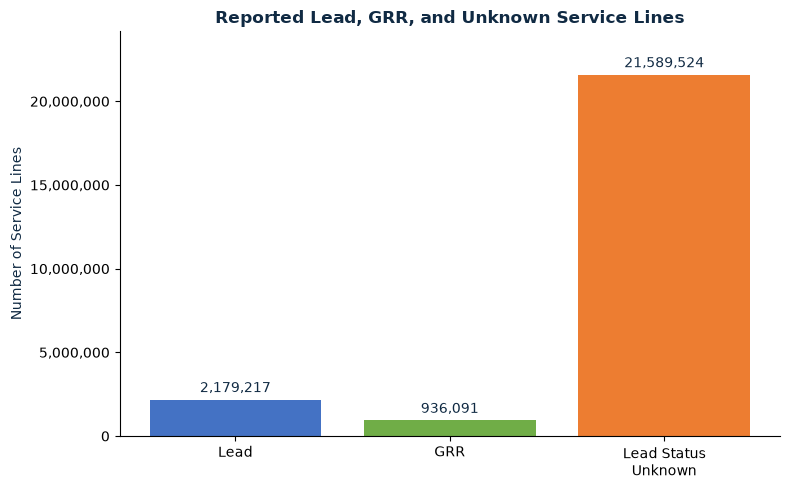

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

display_categories = ["Lead", "GRR", "Lead Status\nUnknown"]

bars = ax.bar(
    display_categories,
    national_totals["Service Lines"],
    color=["#4472C4", "#70AD47", "#ED7D31"]
)

ax.bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in national_totals["Service Lines"]],
    padding=3
)

ax.set_ylim(
    0,
    national_totals["Service Lines"].max() * 1.12
)

ax.set_title("Reported Lead, GRR, and Unknown Service Lines")
ax.set_ylabel("Number of Service Lines")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")

fig.tight_layout()
fig.savefig(OUTPUT / "chart_1_inventory.png", dpi=300, bbox_inches="tight")
plt.show()

### Initial Finding

Within the analytical sample, approximately **3.1 million service lines are already classified as Lead or GRR**, while approximately **21.6 million remain classified as Lead Status Unknown**. The much larger unknown inventory indicates that unresolved identification is a major part of the reported infrastructure picture, but unknown lines should not be interpreted as confirmed lead lines.

## 10. State-Level Infrastructure Needs

State totals are compared to identify where known replacement inventories and unresolved identification needs are most concentrated.

In [21]:
state_summary.sort_values(
    "Known_Replacement",
    ascending=False
)[
    ["State", "Known_Replacement", "Unknown", "Systems"]
].head(10)

,State,Known_Replacement,Unknown,Systems
13,Illinois,672210,529706,1635
35,Ohio,321502,878788,1101
32,New York,289055,951163,2211
22,Michigan,255524,301508,1349
14,Indiana,190947,545507,744
49,Wisconsin,158815,182814,1021
30,New Jersey,135360,860857,555
43,Texas,114501,2178881,4341
38,Pennsylvania,113717,2055512,1770
23,Minnesota,87183,209216,959


In [22]:
top_unknown = (
    state_summary
    .sort_values("Unknown", ascending=False)
    [["State", "Unknown", "Known_Replacement", "Systems"]]
    .head(10)
)

top_unknown

,State,Unknown,Known_Replacement,Systems
43,Texas,2178881,114501,4341
38,Pennsylvania,2055512,113717,1770
9,Florida,1665928,44559,1389
32,New York,951163,289055,2211
25,Missouri,895013,70968,1369
35,Ohio,878788,321502,1101
30,New Jersey,860857,135360,555
33,North Carolina,798785,12934,1906
18,Louisiana,719101,20558,880
2,Arizona,704381,2812,697


In [23]:
top_known_states = set(
    state_summary.nlargest(10, "Known_Replacement")["State"]
)

top_unknown_states = set(
    state_summary.nlargest(10, "Unknown")["State"]
)

overlap = sorted(top_known_states & top_unknown_states)

print(f"States appearing in both top 10 lists: {len(overlap)}")
print(overlap)

States appearing in both top 10 lists: 5
['New Jersey', 'New York', 'Ohio', 'Pennsylvania', 'Texas']


### State-Level Pattern

The largest replacement and identification needs are not concentrated in exactly the same states. Only **5 states** appear in both top-10 lists, indicating that states can face different types of lead service line infrastructure needs.

## 11. Replacement vs. Identification Need

A state-level scatterplot is used to compare known replacement inventory with unresolved identification need across all 50 states and the District of Columbia.

In [24]:
identification_larger = (
    state_summary["Unknown"] > state_summary["Known_Replacement"]
)

identification_larger_count = identification_larger.sum()
state_count = len(state_summary)

print(
    f"States/DC where Identification Need exceeds Known Replacement: "
    f"{identification_larger_count} of {state_count}"
)

States/DC where Identification Need exceeds Known Replacement: 49 of 51


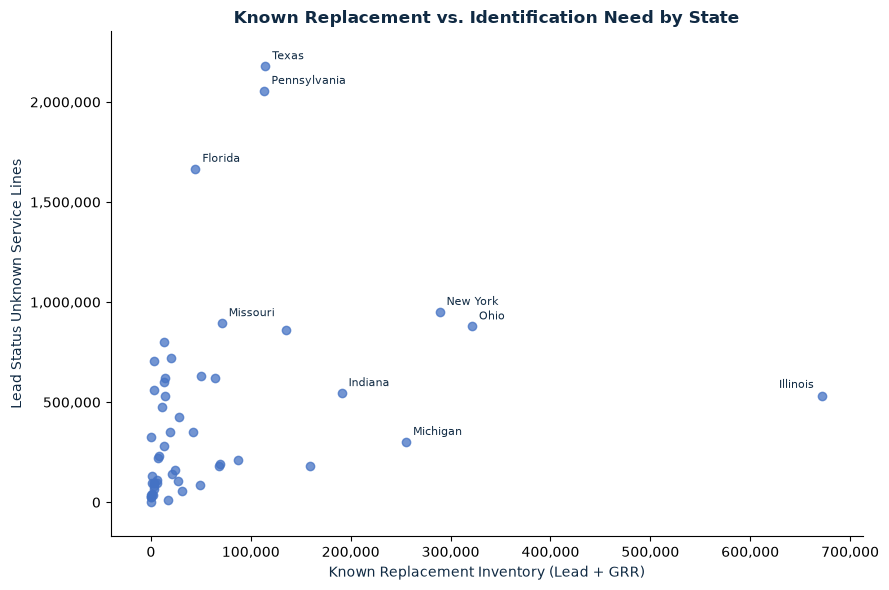

In [25]:
highlight_states = set(
    state_summary.nlargest(5, "Known_Replacement")["State"]
) | set(
    state_summary.nlargest(5, "Unknown")["State"]
)

label_offsets = {
    "Illinois": (-6, 6)
}

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    state_summary["Known_Replacement"],
    state_summary["Unknown"],
    color="#4472C4",
    alpha=0.75
)

for _, row in state_summary[state_summary["State"].isin(highlight_states)].iterrows():
    offset = label_offsets.get(row["State"], (5, 5))
    ax.annotate(
        row["State"],
        (row["Known_Replacement"], row["Unknown"]),
        xytext=offset,
        textcoords="offset points",
        ha="right" if offset[0] < 0 else "left",
        fontsize=8
    )

ax.set_xlabel("Known Replacement Inventory (Lead + GRR)")
ax.set_ylabel("Lead Status Unknown Service Lines")
ax.set_title("Known Replacement vs. Identification Need by State")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.margins(x=0.06, y=0.08)

fig.tight_layout()
fig.savefig(OUTPUT / "chart_4_replacement_vs_identification.png", dpi=300, bbox_inches="tight")
plt.show()

### Relationship between the two inventories
Illinois has the largest known replacement inventory, while Texas and Pennsylvania have the largest Unknown inventories. Ohio and New York also have substantial inventories on both dimensions. These contrasts support different service emphases for further investigation.

In **49 of 51 jurisdictions** (50 states and DC), Unknown inventory exceeds known replacement inventory. This measures reported line counts, not the relative cost, effort, progress, or implementation capacity associated with each type of work. Known replacement planning can proceed while other lines are still being identified.


## 12. Population Context

Raw state totals are influenced by state size, so the analysis also compares service-line inventories relative to population.

The EPA file includes `Population Served Count` at the water-system level, but summing those values across a state may not represent a unique state population. To create a more consistent denominator, this analysis uses **2025 U.S. Census resident population estimates**.

Supplemental population source: U.S. Census Bureau, July 1, 2025 resident population estimates.

**Official source:** [U.S. Census Bureau 2025 resident population estimates](https://www.census.gov/data/datasets/time-series/demo/popest/2020s-national-detail.html)

Because the Census data is only used as a recent size-adjustment benchmark, the one-year timing difference from the 2026 Q2 EPA inventory is considered acceptable.

Normalized measures are reported per **10,000 state residents** and should be interpreted as context for state size, not as direct estimates of affected customers.
    

In [26]:
census_raw = pd.read_csv(
    DATA / "SCPRC-EST2025-18+POP.csv",
    header=None
)

census = census_raw.iloc[:, [0, 1]].copy()
census.columns = ["State", "Population_2025"]

census = census[
    census["State"].astype(str).str.startswith(".")
].copy()

census["State"] = census["State"].str.lstrip(".")

census["Population_2025"] = pd.to_numeric(
    census["Population_2025"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

census.head()

,State,Population_2025
9,Alabama,5193088
10,Alaska,737270
11,Arizona,7623818
12,Arkansas,3114791
13,California,39355309


In [27]:
print(f"Rows in Census state table: {len(census)}")
print(f"Missing population values: {census['Population_2025'].isna().sum()}")

Rows in Census state table: 51
Missing population values: 0


In [28]:
state_summary = state_summary.merge(
    census,
    on="State",
    how="left"
)

print(f"Rows after merge: {len(state_summary)}")
print(f"Missing Census populations: {state_summary['Population_2025'].isna().sum()}")

Rows after merge: 51
Missing Census populations: 0


In [29]:
state_summary["Known_Replacement_per_10k"] = (
    state_summary["Known_Replacement"]
    / state_summary["Population_2025"]
    * 10000
)

state_summary["Unknown_per_10k"] = (
    state_summary["Unknown"]
    / state_summary["Population_2025"]
    * 10000
)

In [30]:
state_summary.sort_values(
    "Known_Replacement_per_10k",
    ascending=False
)[
    ["State", "Known_Replacement_per_10k", "Known_Replacement"]
].head(10)

,State,Known_Replacement_per_10k,Known_Replacement
13,Illinois,528.502672,672210
39,Rhode Island,282.533932,31489
14,Indiana,273.824583,190947
35,Ohio,270.15817,321502
49,Wisconsin,265.897645,158815
22,Michigan,252.297518,255524
8,District of Columbia,247.316711,17155
27,Nebraska,241.386795,48712
15,Iowa,209.826682,67950
23,Minnesota,149.531636,87183


In [31]:
state_summary.sort_values(
    "Unknown_per_10k",
    ascending=False
)[
    ["State", "Unknown_per_10k", "Unknown"]
].head(10)


,State,Unknown_per_10k,Unknown
38,Pennsylvania,1573.967382,2055512
18,Louisiana,1557.106043,719101
31,New Mexico,1539.921468,327310
3,Arkansas,1534.375822,477926
36,Oklahoma,1511.728019,623329
25,Missouri,1427.329795,895013
50,Wyoming,1373.615081,80872
48,West Virginia,1313.741155,232026
34,North Dakota,1225.35835,97950
7,Delaware,1069.482392,113360


In [32]:
raw_known_top10 = set(
    state_summary.nlargest(10, "Known_Replacement")["State"]
)

normalized_known_top10 = set(
    state_summary.nlargest(10, "Known_Replacement_per_10k")["State"]
)

raw_unknown_top10 = set(
    state_summary.nlargest(10, "Unknown")["State"]
)

normalized_unknown_top10 = set(
    state_summary.nlargest(10, "Unknown_per_10k")["State"]
)

print(
    "Known Replacement top-10 overlap:",
    len(raw_known_top10 & normalized_known_top10),
    "of 10"
)

print(
    "Unknown top-10 overlap:",
    len(raw_unknown_top10 & normalized_unknown_top10),
    "of 10"
)


Known Replacement top-10 overlap: 6 of 10
Unknown top-10 overlap: 3 of 10


In [33]:
print("Entered normalized Known Replacement top 10:")
print(sorted(normalized_known_top10 - raw_known_top10))

print("\nDropped from raw Known Replacement top 10:")
print(sorted(raw_known_top10 - normalized_known_top10))

print("\nEntered normalized Unknown top 10:")
print(sorted(normalized_unknown_top10 - raw_unknown_top10))

print("\nDropped from raw Unknown top 10:")
print(sorted(raw_unknown_top10 - normalized_unknown_top10))

Entered normalized Known Replacement top 10:
['District of Columbia', 'Iowa', 'Nebraska', 'Rhode Island']

Dropped from raw Known Replacement top 10:
['New Jersey', 'New York', 'Pennsylvania', 'Texas']

Entered normalized Unknown top 10:
['Arkansas', 'Delaware', 'New Mexico', 'North Dakota', 'Oklahoma', 'West Virginia', 'Wyoming']

Dropped from raw Unknown top 10:
['Arizona', 'Florida', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Texas']


### Population-Adjusted Pattern

Accounting for population changes the state-level picture substantially. Several smaller states rise into the top normalized rankings even though they do not have the largest raw inventories.

This suggests that absolute counts and population-adjusted measures answer different questions: raw totals show where the largest overall workloads are concentrated, while per-capita measures show where those inventories are large relative to state population.

## 13. Final Visualizations

The strongest charts are refined for the final data story using the validated state-level results.

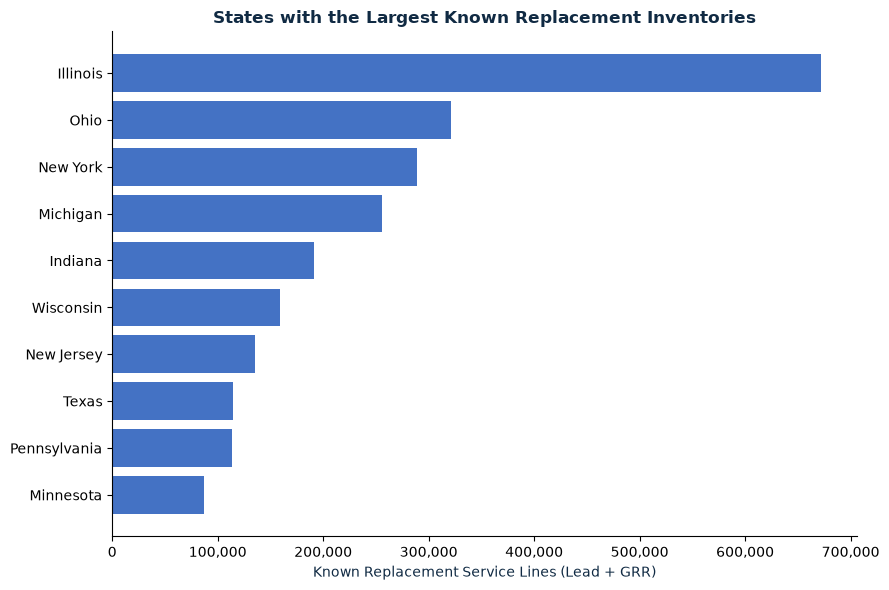

In [34]:
top_known_chart = (
    state_summary.nlargest(10, "Known_Replacement")
    .sort_values("Known_Replacement")
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    top_known_chart["State"],
    top_known_chart["Known_Replacement"],
    color="#4472C4"
)

ax.set_title("States with the Largest Known Replacement Inventories")
ax.set_xlabel("Known Replacement Service Lines (Lead + GRR)")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")

fig.tight_layout()
fig.savefig(OUTPUT / "chart_2_known_replacement.png", dpi=300, bbox_inches="tight")
plt.show()

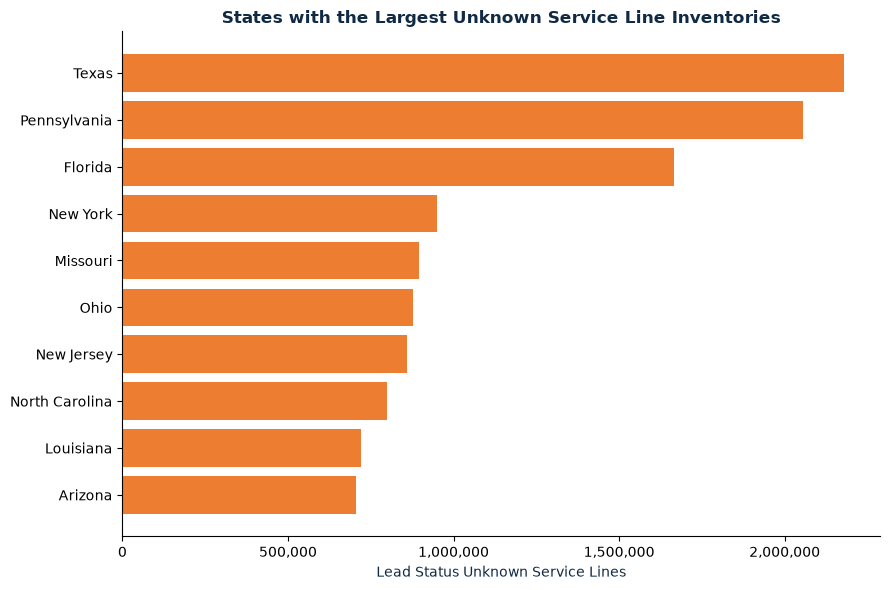

In [35]:
top_unknown_chart = (
    state_summary.nlargest(10, "Unknown")
    .sort_values("Unknown")
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    top_unknown_chart["State"],
    top_unknown_chart["Unknown"],
    color="#ED7D31"
)

ax.set_title("States with the Largest Unknown Service Line Inventories")
ax.set_xlabel("Lead Status Unknown Service Lines")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")

fig.tight_layout()
fig.savefig(OUTPUT / "chart_3_unknown_lines.png", dpi=300, bbox_inches="tight")
plt.show()

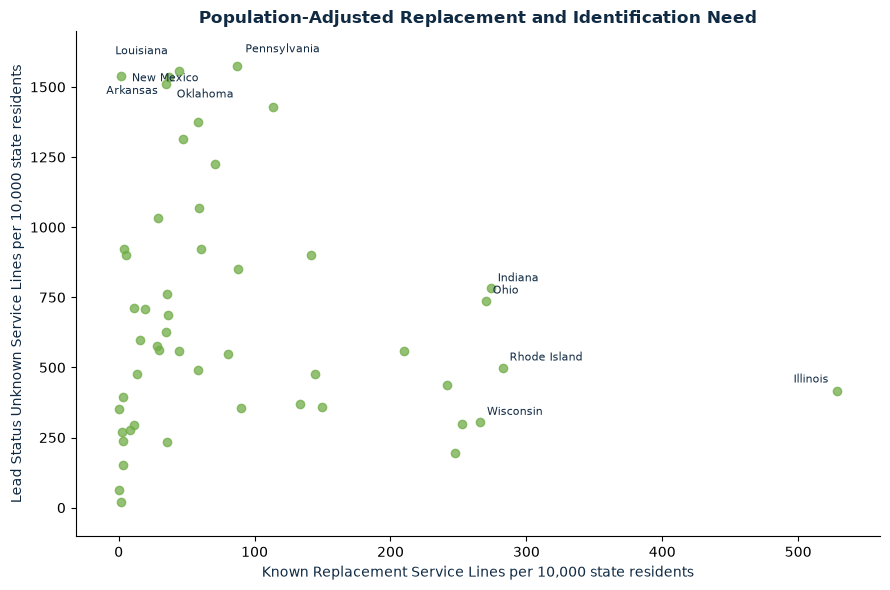

In [36]:
normalized_highlights = set(
    state_summary.nlargest(5, "Known_Replacement_per_10k")["State"]
) | set(
    state_summary.nlargest(5, "Unknown_per_10k")["State"]
)

normalized_label_offsets = {
    "Pennsylvania": (6, 10),
    "Louisiana": (-8, 12),
    "New Mexico": (8, -4),
    "Arkansas": (-8, -12),
    "Oklahoma": (8, -10),
    "Illinois": (-6, 6)
}

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    state_summary["Known_Replacement_per_10k"],
    state_summary["Unknown_per_10k"],
    color="#70AD47",
    alpha=0.75
)

for _, row in state_summary[state_summary["State"].isin(normalized_highlights)].iterrows():
    offset = normalized_label_offsets.get(row["State"], (5, 5))
    ax.annotate(
        row["State"],
        (row["Known_Replacement_per_10k"], row["Unknown_per_10k"]),
        xytext=offset,
        textcoords="offset points",
        ha="right" if offset[0] < 0 else "left",
        fontsize=8
    )

ax.set_title("Population-Adjusted Replacement and Identification Need")
ax.set_xlabel("Known Replacement Service Lines per 10,000 state residents")
ax.set_ylabel("Lead Status Unknown Service Lines per 10,000 state residents")
ax.margins(x=0.06, y=0.08)

fig.tight_layout()
fig.savefig(OUTPUT / "chart_5_normalized.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
state_summary[
    [
        "State",
        "Systems",
        "Lead",
        "GRR",
        "Known_Replacement",
        "Unknown",
        "Population_2025",
        "Known_Replacement_per_10k",
        "Unknown_per_10k"
    ]
].to_csv(OUTPUT / "state_service_line_summary.csv", index=False)

expected_outputs = [
    Path(OUTPUT / "chart_1_inventory.png"),
    Path(OUTPUT / "chart_2_known_replacement.png"),
    Path(OUTPUT / "chart_3_unknown_lines.png"),
    Path(OUTPUT / "chart_4_replacement_vs_identification.png"),
    Path(OUTPUT / "chart_5_normalized.png"),
    Path(OUTPUT / "state_service_line_summary.csv")
]

missing_outputs = [path for path in expected_outputs if not path.exists()]

assert not missing_outputs, f"Missing outputs: {missing_outputs}"

print("All six required output files were created.")

All six required output files were created.


## Reporting coverage and illustrative market comparison

Coverage is the percentage of Community Water Systems listed under each state/DC primacy agency in the source file that meet the complete-report filter. Count unique PWS IDs and verify that each appears once in this denominator. This is a system-count measure, not line coverage; large and small systems receive equal weight.


In [38]:
eligible_cws = raw_df[
    (raw_df["PWS Type"] == "Community water system")
    & raw_df["Primacy Agency"].isin(states_dc)
].copy()
assert eligible_cws["PWS ID"].notna().all()
assert not eligible_cws["PWS ID"].duplicated().any()
coverage = (
    eligible_cws.groupby("Primacy Agency")["PWS ID"].nunique()
    .rename("All_CWS_in_file").reset_index().rename(columns={"Primacy Agency": "State"})
    .merge(state_summary[["State", "Systems"]], on="State", validate="one_to_one")
    .rename(columns={"Systems": "Complete_CWS"})
)
coverage["Excluded_CWS"] = coverage["All_CWS_in_file"] - coverage["Complete_CWS"]
coverage["Complete_report_pct"] = 100 * coverage["Complete_CWS"] / coverage["All_CWS_in_file"]
assert len(coverage) == 51
assert coverage["Complete_report_pct"].between(0, 100).all()
assert coverage["Complete_CWS"].sum() == len(df)
state_results = state_summary.merge(coverage, on="State", validate="one_to_one")
display(coverage.sort_values("Complete_report_pct").head(10).round(1))


,State,All_CWS_in_file,Complete_CWS,Excluded_CWS,Complete_report_pct
29,New Hampshire,706,3,703,0.4
16,Kansas,854,64,790,7.5
47,Washington,2311,1763,548,76.3
31,New Mexico,558,444,114,79.6
9,Florida,1593,1389,204,87.2
36,Oklahoma,889,776,113,87.3
3,Arkansas,659,582,77,88.3
1,Alaska,407,370,37,90.9
43,Texas,4749,4341,408,91.4
13,Illinois,1787,1635,152,91.5


New Hampshire contributes only **3 of 706** listed Community Water Systems (0.4%), and Kansas contributes **64 of 854** (7.5%). Their low sample inventories cannot establish low statewide need. In the five illustrative markets, complete-report coverage ranges from **91.4% to 98.3%** of listed systems. Even high system coverage does not guarantee accurate inventories or representative coverage of service lines. Counts remain unadjusted.

The examples were selected to illustrate contrasting raw inventories, not to establish an exhaustive shortlist. Florida, for example, has the third-largest Unknown inventory and remains relevant to a wider market investigation. Population-adjusted comparisons can also surface smaller states.


In [39]:
market_order = ["Texas", "Pennsylvania", "Illinois", "Ohio", "New York"]
emphasis = {
    "Texas": "Identification emphasis", "Pennsylvania": "Identification emphasis",
    "Illinois": "Replacement-planning emphasis", "Ohio": "Parallel work", "New York": "Parallel work",
}
markets = state_results.set_index("State").loc[market_order].reset_index()
markets["Proposed_emphasis"] = markets["State"].map(emphasis)
display(markets[["State", "Unknown", "Known_Replacement", "Unknown_per_10k",
    "Known_Replacement_per_10k", "Complete_CWS", "All_CWS_in_file",
    "Complete_report_pct", "Proposed_emphasis"]].round(1))


,State,Unknown,Known_Replacement,Unknown_per_10k,Known_Replacement_per_10k,Complete_CWS,All_CWS_in_file,Complete_report_pct,Proposed_emphasis
0,Texas,2178881,114501,687.1,36.1,4341,4749,91.4,Identification emphasis
1,Pennsylvania,2055512,113717,1574.0,87.1,1770,1851,95.6,Identification emphasis
2,Illinois,529706,672210,416.5,528.5,1635,1787,91.5,Replacement-planning emphasis
3,Ohio,878788,321502,738.4,270.2,1101,1125,97.9,Parallel work
4,New York,951163,289055,475.5,144.5,2211,2250,98.3,Parallel work


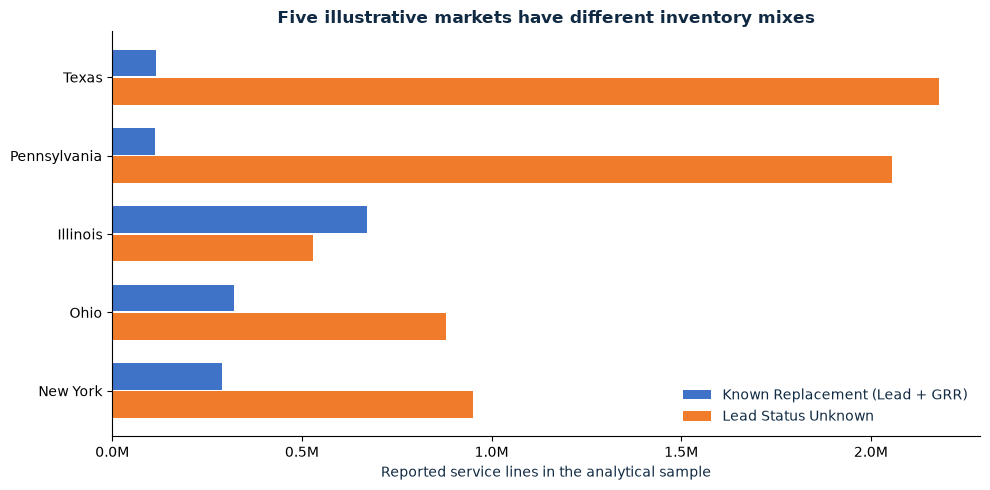

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
y = list(range(len(markets)))
ax.barh([v - 0.18 for v in y], markets["Known_Replacement"], height=0.34,
        color="#3F73C7", label="Known Replacement (Lead + GRR)")
ax.barh([v + 0.18 for v in y], markets["Unknown"], height=0.34,
        color="#F07C2B", label="Lead Status Unknown")
ax.set_yticks(y, markets["State"])
ax.invert_yaxis()
ax.set_xlabel("Reported service lines in the analytical sample")
ax.xaxis.set_major_formatter(lambda value, _: f"{value / 1e6:.1f}M")
ax.set_title("Five illustrative markets have different inventory mixes")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT / "chart_6_illustrative_markets.png", dpi=220, bbox_inches="tight")
plt.show()


In [41]:
# Shared numerical source for the communication artifacts.
assert len(df) == 43993 and df["PWS ID"].nunique() == len(df)
assert total_matches.all()
assert df[["# Lead Service Lines", "# Galvanized Requiring Replacement Service Lines",
           "# Lead Status Unknown Service Lines"]].notna().all().all()
assert (df[numeric_columns].drop(columns="# Non-lead Service Lines") >= 0).all().all()
assert state_results["Population_2025"].gt(0).all()
assert int(state_results["Known_Replacement"].sum()) == 3115308
assert int(state_results["Unknown"].sum()) == 21589524
assert int(identification_larger_count) == 49
assert len(raw_known_top10 & normalized_known_top10) == 6
assert len(raw_unknown_top10 & normalized_unknown_top10) == 3

state_results.to_csv(OUTPUT / "state_service_line_summary.csv", index=False)
coverage.to_csv(OUTPUT / "reporting_coverage.csv", index=False)
markets.to_csv(OUTPUT / "illustrative_markets.csv", index=False)
facts = {
    "inventory_period": "2026 Q2", "population_year": 2025,
    "sample_systems": len(df), "jurisdictions": len(state_results),
    "known_replacement": int(state_results["Known_Replacement"].sum()),
    "unknown": int(state_results["Unknown"].sum()),
    "lead": int(state_results["Lead"].sum()), "grr": int(state_results["GRR"].sum()),
    "unknown_to_known_ratio": float(state_results["Unknown"].sum() / state_results["Known_Replacement"].sum()),
    "identification_larger_jurisdictions": int(identification_larger_count),
    "raw_top10_overlap": len(overlap),
    "known_raw_normalized_top10_overlap": len(raw_known_top10 & normalized_known_top10),
    "unknown_raw_normalized_top10_overlap": len(raw_unknown_top10 & normalized_unknown_top10),
    "all_cws_in_state_scope": len(eligible_cws),
    "markets": json.loads(markets.to_json(orient="records")),
    "states": json.loads(state_results.to_json(orient="records")),
    "sources": {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(DATA.glob("*.csv"))},
    "runtime": {"python": platform.python_version(), **{p: metadata.version(p) for p in ["pandas", "numpy", "matplotlib", "nbformat", "nbclient", "ipykernel"]}},
}
(OUTPUT / "facts.json").write_text(json.dumps(facts, indent=2) + "\n")
print("Validated original findings and exported shared results with reporting coverage.")


Validated original findings and exported shared results with reporting coverage.


## 14. Key Findings

- The analytical sample contains **3,115,308 known replacement service lines** (Lead + GRR) and **21,589,524 Lead Status Unknown service lines**, showing that unresolved identification is substantially larger than the already-classified replacement inventory.
- Known replacement inventory is most concentrated in **Illinois (672,210)**, followed by **Ohio (321,502)** and **New York (289,055)**.
- Identification need is largest in **Texas (2,178,881 Unknown service lines)**, **Pennsylvania (2,055,512)**, and **Florida (1,665,928)**. Only five states appear in both raw top-10 lists, so replacement and identification workloads are not concentrated in exactly the same places.
- Population adjustment changes the interpretation: Illinois remains highest for known replacement inventory at **528.5 per 10,000 residents**, while Pennsylvania leads Unknown inventory at **1,574.0 per 10,000 residents**. The raw and normalized top-10 lists overlap for only **6 of 10** known replacement states and **3 of 10** Unknown states.

## 15. Limitations that affect the recommendation

- **Classification:** Unknown does not mean lead. Unknown lines may ultimately be classified as non-lead.
- **Reporting:** Only complete-report Community Water Systems are included. Coverage differs by jurisdiction. The added coverage measure counts systems listed under each state primacy agency in this file; it does not measure the fraction of all service lines captured or prove representativeness.
- **Geography:** State totals use the file's Primacy Agency field. Territories, Navajo Nation, and directly administered EPA regional records are excluded. State aggregation hides local differences.
- **Population:** The 2025 Census denominator provides size context for 2026 Q2 inventory. It does not represent affected residents or customers, and normalization cannot correct incomplete reporting.
- **Business inference:** Line counts do not establish market revenue, willingness to buy, funding eligibility, project readiness, cost, or service availability at a particular utility.
- **Outcomes:** Inventory does not measure household exposure or water quality. A pilot and its performance metrics are proposals, not demonstrated results.


## 16. Recommendation and proposed pilot process

Use the five illustrative states as starting points for utility screening, with service emphasis determined by each utility's own records. A state label must not be applied automatically to every utility within it.

| Illustrative markets | Proposed emphasis | Reason to investigate | Evidence needed before a pilot |
|---|---|---|---|
| Texas and Pennsylvania | Identification and inventory completion | Largest reported Unknown inventories | Material records, GIS completeness, a feasible verification method, access and funding |
| Illinois | Replacement planning | Largest reported Lead + GRR inventory | Verified line locations, project plans, funding and delivery capacity |
| Ohio and New York | Parallel identification and replacement planning | Substantial inventories on both dimensions | Separate work plans for Unknown and known replacement lines, coordination and capacity |

Illinois still has a large Unknown inventory, and Texas and Pennsylvania still have known replacement work. An emphasis does not exclude other services.

### Fit with documented Xylem capabilities
Xylem's **2022 Asset Performance Optimization brochure**, pages 4–5, describes lead-line detection, inventory development, funding assistance and replacement planning. Its smart asset-management page describes integrating asset and inspection records with investment planning. These sources support a capability fit; they do not validate this market selection or confirm a specific utility engagement. Current service scope would need confirmation before a pilot. Sources were reviewed October 11, 2026. Historical cost figures, regulatory dates, and performance claims in the brochure are not used.

- [Xylem Asset Performance Optimization brochure](https://www.xylem.com/siteassets/brand/decision-intelligence/resources/brochures/dis_brochure_apo_full_09082022_en_us.pdf)
- [Xylem smart asset management](https://www.xylem.com/en-us/applications/smart-asset-management/)

### Proposed sequence and measures
1. **Screen utilities:** Review the inventory mix, reporting quality, GIS and material evidence, funding and local capacity. Select a service emphasis at utility level.
2. **Define a pilot:** Agree on the starting inventory, verification method, scope, costs, access arrangements and ownership of follow-up decisions. Establish the baseline and targets with the utility.
3. **Evaluate:** For identification, track newly classified lines divided by starting Unknown lines in the pilot and cost per newly verified line. For planning, track the share of in-scope known replacement lines with verified locations and an agreed project scope, funding path and delivery schedule. Also record elapsed time and unresolved data gaps.

These are proposed measures, with no numerical performance targets or expected outcomes inferred from the state data. Extend a pilot only after reviewing its observed results and utility constraints.


## 17. Recommended next question

**Which utilities in the candidate markets have the inventory needs, data, funding, and capacity to support a pilot?**

Answering this requires utility-level investigation. This portfolio remaster stops at state screening and a proposed assessment process.
